<h1> Project 1: Data Modeling <h1>

<h1>Set Directory<h1>

In [1]:
import os
new_directory = (r"C:\Users\billy\Repositories\MEE-460\Project 2") #Desktop
#new_directory = (r"C:\Users\billy\Repositories\MEE-460\Project 2") #Surface
os.chdir(new_directory)

<h2>Assignment Details in this file<h2>
<h5><p>Determine the score
Choose the best performing model (highest score on testing data)
In a Jupyter notebook, present model accuracy using a combination of categorical plots and confusion matrices.<p><h5>

# Random Forest Classifier Stacking

In [2]:
import pickle as pkl
import time #This is for timing the code
#StartTime = time.time()
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) #eliminates future version warnings 
import pandas as pd
import seaborn as sns #These are the packages for the random forest, we must write the code for the neural network. 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier #This is the random forest classifier
from sklearn.datasets import make_classification #This is a package that generates random data for testing
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from pickle import dump
import numpy as np
import random as rn
import os
from sklearn.preprocessing import LabelEncoder #This is for encoding the data. This gives the collision types a numerical value to associate them with the numeric data. 

# Stack the models in file 
df = pd.read_csv('RFC_results.csv')

# Sort by 'R2 Score' in descending order to get the best scores
df = df.sort_values(by='Test Score', ascending=False)

# Select the top 10 models
top_model = df[:1]
print(top_model)
WorstModel = df[9:]
print(WorstModel)

   cv  error_score  estimator__bootstrap  estimator__ccp_alpha  \
7  10          NaN                  True                   0.0   

   estimator__class_weight estimator__criterion  estimator__max_depth  \
7                      NaN                 gini                   NaN   

  estimator__max_features  estimator__max_leaf_nodes  estimator__max_samples  \
7                    sqrt                        NaN                     NaN   

   ...  pre_dispatch  random_state  refit  return_train_score  scoring  \
7  ...      2*n_jobs             7   True                True      NaN   

   verbose  Train Score  Test Score  R2 Score  Model Number  
7        2     0.985714         1.0  0.905462             7  

[1 rows x 34 columns]
   cv  error_score  estimator__bootstrap  estimator__ccp_alpha  \
9  10          NaN                  True                   0.0   

   estimator__class_weight estimator__criterion  estimator__max_depth  \
9                      NaN                 gini          

Load the original dataset

In [4]:
Training_df = pd.read_excel("output.xlsx")
Training_df.head()
results = pd.DataFrame() #This is the dataframe that will store the results of the model training. This is added to solve a concatenation issue of the parameters
rfscores = {}
scores = {}
r2Train = {}


Organize original data set

In [5]:
X = np.array(Training_df[['Fx1' , 'Fy1', 'Fz1', 'Tx1', 'Ty1', 'Tz1', 'Fx2', 'Fy2', 'Fz2', 'Tx2', 'Ty2', 'Tz2', 'Fx3', 'Fy3', 'Fz3', 'Tx3', 'Ty3', 'Tz3', 'Fx4', 'Fy4', 'Fz4', 'Tx4', 'Ty4', 'Tz4', 'Fx5', 'Fy5', 'Fz5', 'Tx5', 'Ty5', 'Tz5', 'Fx6', 'Fy6', 'Fz6', 'Tx6', 'Ty6', 'Tz6', 'Fx7', 'Fy7', 'Fz7', 'Tx7', 'Ty7', 'Tz7', 'Fx8', 'Fy8', 'Fz8', 'Tx8', 'Ty8', 'Tz8', 'Fx9', 'Fy9', 'Fz9', 'Tx9', 'Ty9', 'Tz9', 'Fx10', 'Fy10', 'Fz10', 'Tx10', 'Ty10', 'Tz10', 'Fx11', 'Fy11', 'Fz11', 'Tx11', 'Ty11', 'Tz11', 'Fx12', 'Fy12', 'Fz12', 'Tx12', 'Ty12', 'Tz12', 'Fx13', 'Fy13', 'Fz13', 'Tx13', 'Ty13', 'Tz13', 'Fx14', 'Fy14', 'Fz14', 'Tx14', 'Ty14', 'Tz14', 'Fx15', 'Fy15', 'Fz15', 'Tx15', 'Ty15', 'Tz15']])
Y = np.array(Training_df[['Collision Type']]) #This is the output data that the model will predict.

LabelEncoder = LabelEncoder()
Y = LabelEncoder.fit_transform(Y)

c:\Users\billy\anaconda3\envs\myenv\lib\site-packages\sklearn\preprocessing\_label.py:114: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Load best model of the 10 RFC models

In [6]:
# The best model is overfit at 1.0 for test score. I will try this one and another at a lower score. 
from pickle import load
BestRFCModel = load(open(f'RFC_model{int(top_model["Model Number"].values[0])}.pkl', 'rb'))
BestRFCModelData = load(open(f'RFC_model_XY_TrainTest{int(top_model["Model Number"].values[0])}.pkl', 'rb'))
X_train_BestRFC = BestRFCModelData['X_train']
Y_train_BestRFC = BestRFCModelData['Y_train']
X_test_BestRFC = BestRFCModelData['X_test']
Y_test_BestRFC = BestRFCModelData['Y_test']

c:\Users\billy\anaconda3\envs\myenv\lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.3.0 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\billy\anaconda3\envs\myenv\lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.3.0 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\billy\anaconda3\envs\myenv\lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator RandomizedSearchCV from version 1.3.0 

Confusion Matrices and plots for the RFC models

In [7]:
from sklearn.metrics import classification_report, confusion_matrix


In [8]:
current_dir = os.getcwd()
print(current_dir)


C:\Users\billy\Repositories\MEE-460\Project 2


Test the best RFC model on the dataset. 

In [10]:
StartTime = time.time()
# ******************** Train the Model ***************************************
for seed in range(10):    #trains 10 models. The seed determines how initilization and randomization of each model is done

    os.environ['PYTHONHASHSEED'] = '0'   #To rn.seed, this code keeps randomization and splitting concistent for each model run
    os.environ['CUDA_VISIBLE_DEVICES'] = '0'
    np.random.seed(seed)
    rn.seed(seed)


    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=seed) #test size can be changed but not to beyond .30. This symbolizes %  of dataset used for testing, and the rest is training. 
    
    #Merge X_train, X_test, y_train, Y_test and save per iteration 
    seeded_df = [X_train, Y_train, Y_train, Y_test]
    scalerX = StandardScaler() #This is data normalization for data that changes larger orders of magnitude.
    scalerX.fit(X) #This fits the scaling to the X-Data  
    X_train = scalerX.transform(X_train) 
    X_test = scalerX.transform(X_test)

    # Random forest hyperparamter optimization parameters
    # Number of trees in random forest
    n_estimators = [int(x) for x in np.linspace(start = 200, stop = 2000, num = 10)] #How man trees will be generated
    # Number of features to consider at every split
    max_features = [1.0, 'sqrt', 'log2']
    # Maximum number of levels in tree
    max_depth = [int(x) for x in np.linspace(10, 110, num = 11)] #How deep the branches can go
    max_depth.append(None)
    # Minimum number of samples required to split a node
    min_samples_split = [int(x) for x in np.linspace(2, 50, num = 25)]
    #Minimum number of samples required at each leaf node
    min_samples_leaf = [int(x) for x in np.linspace(1, 50, num = 1)]
    # Method of selecting samples for training each tree
    bootstrap = [True, False]
    # Create the random grid
    random_grid = {'n_estimators': n_estimators,
                   'max_features': max_features,
                   'max_depth': max_depth,
                   'min_samples_split': min_samples_split,
                   'min_samples_leaf': min_samples_leaf,
                   'bootstrap': bootstrap}
   
    # Use the random grid to search for best hyperparameters
    # First create the base model to tune
    rf = RandomForestClassifier() 

    rf_random = RandomizedSearchCV(estimator = rf, param_distributions = random_grid, n_iter = 100, cv = 10, verbose=2, random_state=seed, n_jobs = -1, return_train_score=True) #This is the optimizing function that will create a better model. n_iter can be increased to 1000+
    # Fit the random search model
    rf_random.fit(X_train, Y_train.reshape(-1,))
    # Determine Model prediction for train and test
    cv_results = rf_random.cv_results_

    ScoreTrain = rf_random.score(X_train, Y_train) 
    #rSquaredtrain = print('nn Train Score of' + str( seed ) + ' is ' + str(ScoreTrain))
    ScoreTest = rf_random.score(X_test, Y_test)
    #rSquaredtest = print('nn Test Score of' + str( seed ) + ' is ' + str(ScoreTest))
    scores[seed] = (ScoreTrain, ScoreTest)
    modelNumber = seed
    predictionTrain = rf_random.predict(X_train)
    R2score = r2_score(Y_train, predictionTrain)
   # Get the model's parameters
    params = rf_random.get_params()
    params['Train Score'] = ScoreTrain
    params['Test Score'] = ScoreTest
    params['R2 Score'] = R2score
    params['Model Number'] = modelNumber
    
    # Append the results to the DataFrame
    params_df = pd.DataFrame([params])
    results = pd.concat([results, params_df], ignore_index=True)
    results.to_csv('TestModelRFC_results.csv', index=False)
    SeededDictRF = {'model': modelNumber, 
                    'X_train': X_train, 
                    'X_test': X_test, 
                    'Y_train': Y_train, 
                    'Y_test': Y_test,
                    'Train Score': ScoreTrain,
                    'Test Score': ScoreTest}
    pickle_file_path = os.path.join(current_dir, 'TestForBestRFC_model_XY_TrainTest' + str(seed) + '.pkl')
    pickle_model_path = os.path.join(current_dir, 'TestForBestRFC_model' + str(seed) + '.pkl')
    dump(SeededDictRF, open(pickle_file_path, 'wb'))
    # ******************** Save Model ***************************************
    dump(rf_random, open(pickle_model_path, 'wb')) #The pickle load function will be able to pull the model     

# ******************** Time the Model ***************************************

EndTime = time.time()
RunTime = EndTime - StartTime
print(f"The runtime of the program is {RunTime} seconds.")

Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
Fitting 10 folds for each of 100 candidates, totalling 1000 fits
The runtime of the program is 322.3606822490692 seconds.


In [11]:
from sklearn.metrics import accuracy_score

In [13]:
predictionsRFC = rf_random.predict(X_test)
print("Accuracy of a base model:", accuracy_score(Y_test, predictionsRFC))
predictionsBestRFC = rf_random.predict(X_test_BestRFC)
print("Accuracy of the best model:", accuracy_score(Y_test_BestRFC, predictionsBestRFC))

print(confusion_matrix(Y_test, predictionsRFC))
print(classification_report(Y_test, predictionsRFC))

print(confusion_matrix(Y_test_BestRFC, predictionsBestRFC))
print(classification_report(Y_test_BestRFC, predictionsBestRFC))


Accuracy of a base model: 0.7222222222222222
Accuracy of the best model: 1.0
[[2 0 0 0]
 [0 3 2 0]
 [0 0 3 0]
 [2 1 0 5]]
              precision    recall  f1-score   support

           0       0.50      1.00      0.67         2
           1       0.75      0.60      0.67         5
           2       0.60      1.00      0.75         3
           3       1.00      0.62      0.77         8

    accuracy                           0.72        18
   macro avg       0.71      0.81      0.71        18
weighted avg       0.81      0.72      0.73        18

[[2 0 0 0]
 [0 3 0 0]
 [0 0 7 0]
 [0 0 0 6]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         7
           3       1.00      1.00      1.00         6

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg      

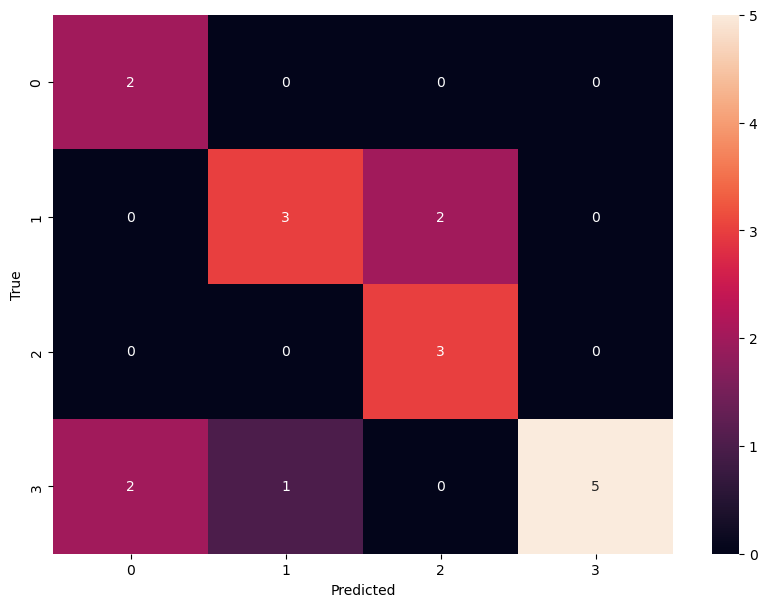

In [14]:
y_true = Y_test
y_pred = predictionsRFC

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create a heatmap
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

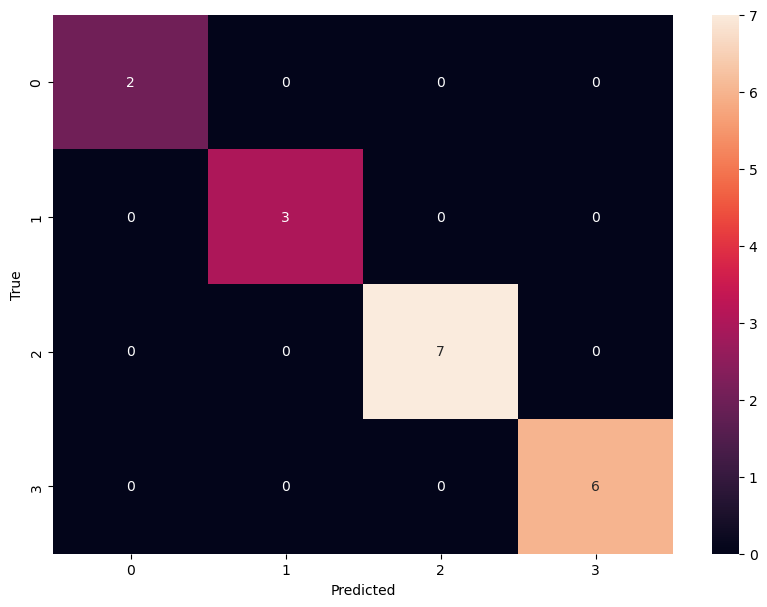

In [15]:
y_true = Y_test_BestRFC
y_pred = predictionsBestRFC

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create a heatmap
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

Categorical Plots

<h1>Logistic Regression Best Model Testing<h1>

Import additional necessary packages

In [16]:
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

Load the best model

In [17]:
dflr = pd.read_csv('lr_results.csv')

# Sort by 'R2 Score' in descending order to get the best scores
dflr = dflr.sort_values(by='Test Score', ascending=False)

# Select the top 10 models
top_modellr = dflr[:1]
print(top_modellr)
WorstModellr = dflr[9:]
print(WorstModellr)

   cv  error_score  estimator__C  estimator__class_weight  estimator__dual  \
7 NaN          NaN           1.0                      NaN            False   

   estimator__fit_intercept  estimator__intercept_scaling  \
7                      True                             1   

   estimator__l1_ratio  estimator__max_iter estimator__multi_class  ...  \
7                  NaN                  100                   auto  ...   

                                          param_grid pre_dispatch  refit  \
7  {'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000], 'p...     2*n_jobs   True   

  return_train_score                      scoring  verbose  Train Score  \
7               True  make_scorer(accuracy_score)        0     0.914286   

  Test Score  R2 Score Model Number  
7   0.833333  0.821429            7  

[1 rows x 29 columns]
   cv  error_score  estimator__C  estimator__class_weight  estimator__dual  \
2 NaN          NaN           1.0                      NaN            False   

   estima

Load the logistic regression best model and initialize dictionaries for results

In [20]:
resultslr = pd.DataFrame() #This is the dataframe that will store the results of the model training. This is added to solve a concatenation issue of the parameters
lrscores = {}
scores_lr = {}
r2Trainlr = {}

BestLRModel = load(open(f'lr_model{int(top_model["Model Number"].values[0])}.pkl', 'rb'))
BestLRModelData = load(open(f'lr_model_XY_TrainTest{int(top_model["Model Number"].values[0])}.pkl', 'rb'))
X_train_BestLR = BestLRModelData['X_train']
Y_train_BestLR = BestLRModelData['Y_train']
X_test_BestLR = BestLRModelData['X_test']
Y_test_BestLR = BestLRModelData['Y_test']
# X_predict_BestLR = BestLRModelData['X_predict']
# Y_predict_BestLR = BestLRModelData['Y_predict']

AttributeError: Can't get attribute '_PredictScorer' on <module 'sklearn.metrics._scorer' from 'c:\\Users\\billy\\anaconda3\\envs\\myenv\\lib\\site-packages\\sklearn\\metrics\\_scorer.py'>

Use the best LR model data to test against the dataset once again. 

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV

In [ ]:
for seed in range(1):    #trains 10 models. The seed determines how initilization and randomization of each model is done

    os.environ['PYTHONHASHSEED'] = '0'   #To rn.seed, this code keeps randomization and splitting concistent for each model run
    os.environ['CUDA_VISIBLE_DEVICES'] = '0'
    np.random.seed(seed)
    rn.seed(seed)

    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, random_state=seed) 
    #test size can be changed but not to beyond .30. This symbolizes %  of dataset used for testing, and the rest is training. 

    #Merge X_train, X_test, y_train, Y_test and save per iteration
    seeded_df = [X_train, Y_train, Y_train, Y_test]
    scalerX = StandardScaler() #This is data normalization for data that changes larger orders of magnitude.
    scalerX.fit(X) #This fits the scaling to the X-Data  
    X_train = scalerX.transform(X_train) 
    X_test = scalerX.transform(X_test)
    Y_train = Y_train.ravel()

    lr = LogisticRegression()
    Score = make_scorer(accuracy_score)

    param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100, 1000], 
              'penalty': ['l1', 'l2'],
              'dual': [True, False]}

    lr_grid = GridSearchCV(estimator=lr, param_grid=param_grid, scoring=Score, n_jobs=-1, return_train_score=True)
    # lr_grid = GridSearchCV(estimator = lr, penalty=None , dual=False, C=1.0, kparam_grid = ParamGrid, cv = 10, verbose=2, n_jobs = -1, return_train_score=True, scoring=Score)
    #lr_grid = GridSearchCV(estimator = lr, C=1.0, fit_intercept=True, intercept_scaling=0, tol=0.0001, class_weight=None, random_state=seed, solver='sag', max_iter=100, multi_class='auto', verbose=0, warm_start=False, n_jobs=-1, return_train_score=True, scoring=Score) 
    lr_grid.fit(X_train, Y_train.reshape(-1,))
    # Determine Model prediction for train and test
    cv_results = lr_grid.cv_results_

    ScoreTrain = lr_grid.score(X_train, Y_train) 
    #rSquaredtrain = print('nn Train Score of' + str( seed ) + ' is ' + str(ScoreTrain))
    ScoreTest = lr_grid.score(X_test, Y_test)
    #rSquaredtest = print('nn Test Score of' + str( seed ) + ' is ' + str(ScoreTest))
    scores[seed] = (ScoreTrain, ScoreTest)
    modelNumber = seed
    predictionTrain = lr_grid.predict(X_train)
    R2score = r2_score(Y_train, predictionTrain)

   # Get the model's parameters
    params = lr_grid.get_params()
    params['Train Score'] = ScoreTrain
    params['Test Score'] = ScoreTest
    params['R2 Score'] = R2score
    params['Model Number'] = modelNumber
    
    # Append the results to the DataFrame
    params_df = pd.DataFrame([params])
    resultslr = pd.concat([results, params_df], ignore_index=True)
    resultslr.to_csv('BestLR_results.csv', index=False)
    SeededDictRF = {'model': modelNumber, 
                    'X_train': X_train, 
                    'X_test': X_test, 
                    'Y_train': Y_train, 
                    'Y_test': Y_test,
                    'Train Score': ScoreTrain,
                    'Test Score': ScoreTest}
    
    pickle_file_path = os.path.join(current_dir, 'Best_lr_model_XY_TrainTest' + str(seed) + '.pkl')
    pickle_model_path = os.path.join(current_dir, 'Best_lr_model' + str(seed) + '.pkl')
    dump(SeededDictRF, open(pickle_file_path, 'wb'))
    # ******************** Save Model ***************************************
    dump(lr_grid, open(pickle_model_path, 'wb')) #The pickle load function will be able to pull the model     

# ******************** Time the Model ***************************************
EndTime = time.time()
RunTime = EndTime - StartTime
print(f"The runtime of the program is {RunTime} seconds.")


In [52]:
predictionsLR = lr_grid.predict(X_test)
print("Accuracy of a base model:", accuracy_score(Y_test, predictionsLR))
Y_test_scorelr = accuracy_score(Y_test, predictionsLR)
predictionsBestLR = lr_grid.predict(X_test_BestLR)
print("Accuracy of the best model:", accuracy_score(Y_test_BestLR, predictionsBestLR))
Y_test_scoreBestlr = accuracy_score(Y_test_BestLR, predictionsBestLR)
print(confusion_matrix(Y_test, predictionsLR))
print(classification_report(Y_test, predictionsLR))

print(confusion_matrix(Y_test_BestLR, predictionsBestLR))
print(classification_report(Y_test_BestLR, predictionsBestLR))

Accuracy of a base model: 0.7777777777777778


TypeError: missing a required argument: 'y_pred'

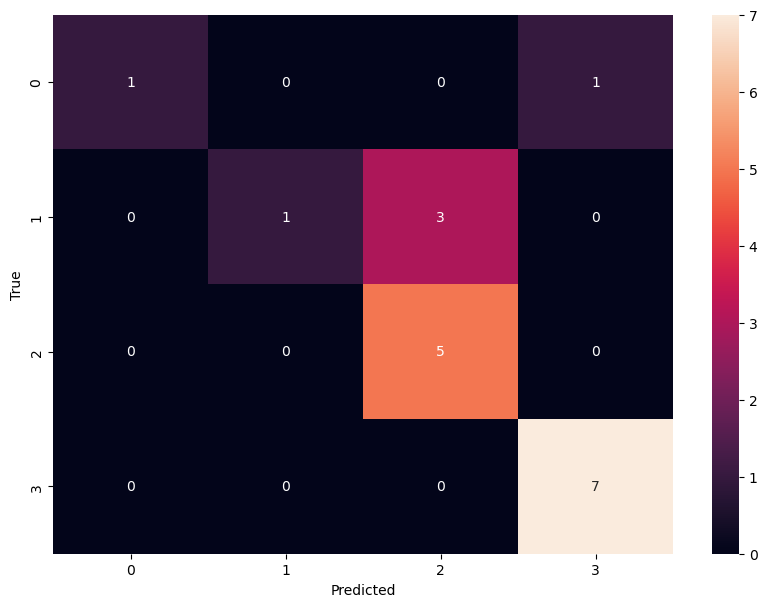

In [46]:
y_true = Y_test
y_pred = predictionsLR

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create a heatmap
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

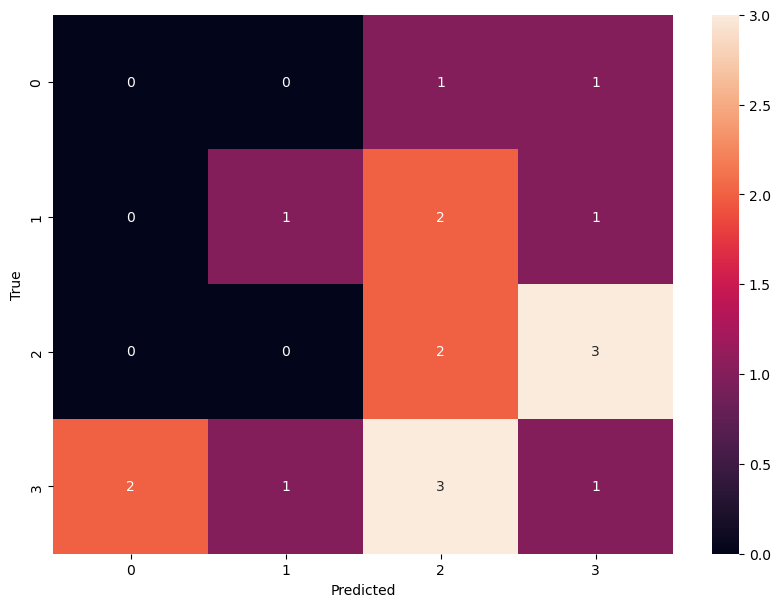

In [47]:
y_true = Y_test
y_pred = predictionsBestLR

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Create a heatmap
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.show()

Categorical Plots

In [50]:
from sklearn.metrics import roc_curve, auc


In [ ]:
y_test = Y_test
y_score = Y_test_scorelr
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()